In [25]:
from sklearn._config import set_config
from sklearn.metrics import (
    r2_score,
    mean_absolute_error
)
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.model_selection import GridSearchCV, train_test_split
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np
from sklearn.preprocessing import StandardScaler, OneHotEncoder

RandomForestRegressor

r2_score: 0.87
On average, my price guess is off by: $44,668.25


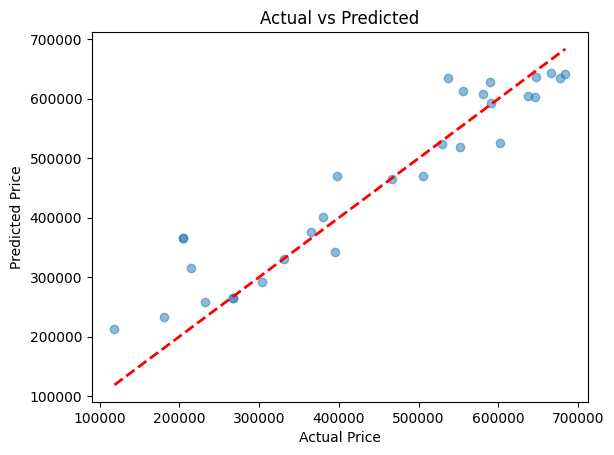

In [ ]:
set_config(transform_output='pandas')
df = pd.read_csv("estate_price.csv")

X = df.drop(columns='price')
y = df['price']

# create training split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)
#preprocess data

numeric_features = X.select_dtypes(include=['int64', 'float64']).columns
categorical_features = X.select_dtypes(include=['str', 'category']).columns
preprocess_data = ColumnTransformer(
    transmformers=[
        ('scaler', StandardScaler(), numeric_features),
        ('encoder', OneHotEncoder(sparse_output=False), categorical_features)
    ]
)
# create Pipeline
pipe = Pipeline([
    ('prep', preprocess_data),
    ('model', RandomForestRegressor(random_state=42))
])

# create gridseach cv
model = GridSearchCV(
    estimator=pipe,
    param_grid={
        'model__n_estimators': [15],
        'model__max_depth': [15],
        'model__min_samples_split': [2, 5]
    },
    scoring=['neg_mean_absolute_error', 'r2'],
    refit='neg_mean_absolute_error',
    cv=5
)

# train data
model.fit(X_train, y_train)

#predict
model_prediction = model.predict(X_test)

r_score = r2_score(y_test, model_prediction) 
print(f"r2_score: {r_score:.2f}")

mae = mean_absolute_error(y_test, model_prediction)
print(f"On average, my price guess is off by: ${mae:,.2f}")

colors = ['green', 'red']
plt.scatter(y_test, model_prediction, alpha=0.5)
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--', lw=2)

plt.xlabel('Actual Price')
plt.ylabel('Predicted Price')
plt.title('Actual vs Predicted')
plt.show()


GradientBoostingRegressor

r2_score: 0.80
On average, my price guess is off by: $59,784.57


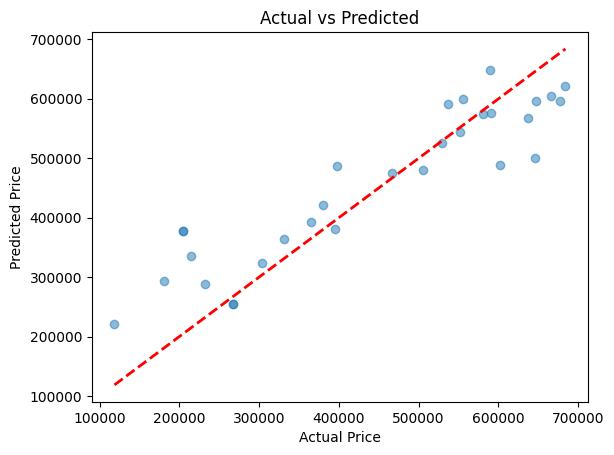

In [27]:
set_config(transform_output='pandas')
df = pd.read_csv("estate_price.csv")

X = df.drop(columns='price')
y = df['price']

# create training split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

#preprocess data

numeric_features = X.select_dtypes(include=['int64', 'float64']).columns
preprocess_data = ColumnTransformer(
    transformers=[
        ('scaler', StandardScaler(), numeric_features),
    ]
)
# create Pipeline
pipe = Pipeline([
    ('prep', preprocess_data),
    ('model', GradientBoostingRegressor(random_state=42))
])

# create gridseach cv
model = GridSearchCV(
    estimator=pipe,
    param_grid={
        'model__n_estimators': [15],
        'model__max_depth': [5],
        'model__min_samples_split': [2]
    },
    scoring=['neg_mean_absolute_error', 'r2'],
    refit='neg_mean_absolute_error',
    cv=5
)

# train data
model.fit(X_train, y_train)

#predict
model_prediction = model.predict(X_test)

r_score = r2_score(y_test, model_prediction) 
print(f"r2_score: {r_score:.2f}")

mae = mean_absolute_error(y_test, model_prediction)
print(f"On average, my price guess is off by: ${mae:,.2f}")

colors = ['green', 'red']
plt.scatter(y_test, model_prediction, alpha=0.5)
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--', lw=2)

plt.xlabel('Actual Price')
plt.ylabel('Predicted Price')
plt.title('Actual vs Predicted')
plt.show()
